## Dictionary Attack

In this notebook, we load the surrogate model we have calculated in [this notebook](./model_dist) and apply it to the dictionary attack notebook from the last homework.

**Goal & Dataset:**

Now, we want to find an input that maximize the models confidence for the "classX" targets. Since we do not know what these classes could describe we want to use a dataset that contains a great variety of different topics and things. Therefore, we choose the X from dataset.

Furthermore, we also want to try the following. Since CLIP has a joint embedding space for images and labels, we take the Wordnet dataset and embedd it. Then we act similar to the image dataset and try to find terms that maximize the "classX" targets using our surrogate model.

In [36]:
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu132
%pip install faiss-cpu==1.15.1 numpy==2.5.4 open-clip-torch==3.3.0 datasets==5.1.0 matplotlib==3.11.2 tqdm==4.70.1

Note: you may need to restart the kernel to use updated packages.


c:\Users\kelle\Documents\projects\uni-MultiModal\homework_2\.venv\Scripts\python.exe: No module named pip


Note: you may need to restart the kernel to use updated packages.


c:\Users\kelle\Documents\projects\uni-MultiModal\homework_2\.venv\Scripts\python.exe: No module named pip


In [51]:
import io
import base64
import numpy as np
import requests
import torch
import torch.nn as nn
import joblib

from transformers import CLIPModel, CLIPProcessor
from transformers.modeling_outputs import BaseModelOutputWithPooling
from datasets import load_dataset
from matplotlib import pyplot as plt
from tqdm import tqdm
from pathlib import Path
from PIL import Image

In [ ]:
SEED = 42

# Define target inference server URL
TARGET_SERVER_URL = "https://wstud-mmml26-classification.web.webis.de/predict"
MAX_REQUESTS = 50

HG_DATASET = "j-reber/imagenet_reduced_trainingset-single_sample"

# Surrogate model
MODEL_PATH = "./.cache/domainnet/surrogate_al.joblib"
CLASSES = ["class1", "class2", "class3", "class4"]
BATCH_SIZE = 64

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

### 2. Load & Preprocess dataset

In [39]:
df = load_dataset(HG_DATASET).shuffle(seed=SEED)
train_data = df["train"]

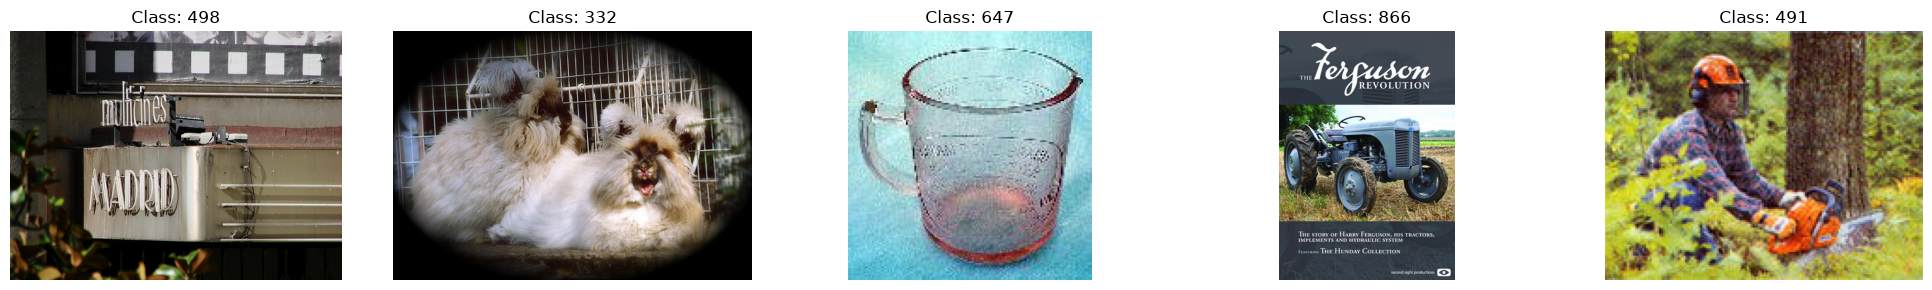

In [40]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3))

for i in range(5):
    sample = train_data[i]
    
    image = sample["image"]
    label = sample["label"]
    
    axes[i].imshow(image, cmap="gray")
    axes[i].set_title(f"Class: {label}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

### 3. Embed dataset using surrogate model & Index it

In [41]:
### load surrogate model
sur = joblib.load(MODEL_PATH)
BACKBONE, KIND, head_sk = sur["backbone"], sur["kind"], sur["model"]

clip_backbone = CLIPModel.from_pretrained(BACKBONE).to(DEVICE).eval()
proc = CLIPProcessor.from_pretrained(BACKBONE)

def T(a):
    return torch.tensor(a, dtype=torch.float32)

class RidgeHead(nn.Module):
    def __init__(self, m):
        super().__init__()
        self.lin = nn.Linear(m.coef_.shape[1], m.coef_.shape[0])
        self.lin.weight.data = T(m.coef_)
        self.lin.bias.data = T(m.intercept_)
    def forward(self, x):
        return self.lin(x)

class MLPHead(nn.Module):
    def __init__(self, pipe):
        super().__init__()
        sc, mlp = pipe.named_steps["standardscaler"], pipe.named_steps["mlpregressor"]
        assert mlp.activation == "relu"
        self.register_buffer("mu", T(sc.mean_))
        self.register_buffer("sd", T(sc.scale_))
        self.layers = nn.ModuleList()
        for W, b in zip(mlp.coefs_, mlp.intercepts_): 
            l = nn.Linear(*W.shape)
            l.weight.data, l.bias.data = T(W.T), T(b)
            self.layers.append(l)
    def forward(self, x):
        x = (x - self.mu) / self.sd
        for i, l in enumerate(self.layers):
            x = l(x)
            if i < len(self.layers) - 1:
                x = torch.relu(x)
        return x

surrogate_head = (RidgeHead(head_sk) if KIND == "ridge" else MLPHead(head_sk)).to(DEVICE).eval()

def embed(pixel_values):
    f = clip_backbone.get_image_features(pixel_values=pixel_values)
    if isinstance(f, BaseModelOutputWithPooling):
        f = f.pooler_output
    return torch.nn.functional.normalize(f, dim=-1)

def surrogate_logits(pixel_values):
    return surrogate_head(embed(pixel_values))

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 6842.71it/s]


In [ ]:
### encode the dataset images
@torch.inference_mode()
def embed_images(images):
    imgs = [img.convert("RGB") for img in images]
    for img in imgs:
        img.thumbnail((1024, 1024))
    px = proc(images=imgs, return_tensors="pt")["pixel_values"].to(DEVICE)
    feats = embed(px)
    logits = surrogate_head(feats)
    return feats.float().cpu().numpy(), logits.float().cpu().numpy()

emb_chunks, logit_chunks = [], []
for start in tqdm(range(0, len(train_data), BATCH_SIZE), desc="Embedding"):
    e, z = embed_images(train_data[start:start + BATCH_SIZE]["image"])
    emb_chunks.append(e)
    logit_chunks.append(z)

embeddings = np.ascontiguousarray(np.concatenate(emb_chunks), dtype="float32")
surrogate_z = np.concatenate(logit_chunks)

print(embeddings.shape, surrogate_z.shape)

Embedding: 100%|██████████| 16/16 [00:24<00:00,  1.55s/it]

(1000, 512) (1000, 2)


### 4. Conduct dictionary attack

In [52]:
session = requests.Session()

def parse_img_tobase64(image: Image.Image) -> str:
    img = image.convert("RGB")
    img.thumbnail((1024, 1024), Image.LANCZOS)
    buf = io.BytesIO()
    img.save(buf, format="PNG")
    return base64.b64encode(buf.getvalue()).decode("utf-8")

def query_api(image):
    try:
        resp = session.post(
            TARGET_SERVER_URL,
            json={"image": parse_img_tobase64(image), "classes": CLASSES},
            timeout=30,
        )
        resp.raise_for_status()
        return resp.json()["classes"]
    except Exception as e:
        print(f"Request failed {e}")
        return None

def evaluate_candidates(indices, target, desc):
    results = []
    for idx in tqdm(indices, desc=desc):
        probs = query_api(train_data[int(idx)]["image"])
        if probs is not None:
            results.append({"idx": int(idx), "score": probs[target]})
    return sorted(results, key=lambda r: r["score"], reverse=True)


TARGET_DIR = {"class1": (0, -1), "class2": (0, +1),
              "class3": (1, +1), "class4": (1, -1)}

def dictionary_attack(target, budget=MAX_REQUESTS):
    col, sign = TARGET_DIR[target]
    score = sign * surrogate_z[:, col]
    cand = np.argsort(-score)[:budget]     # best candidate according to surrogate
    return evaluate_candidates(cand, target, desc=f"Attack ({target})")

In [53]:
attacks = {}
for c in CLASSES:
    attacks[c] = dictionary_attack(c)
    print(f"Dictionary attack against {c}: best idx={attacks[c][0]['idx']:6d}  score={attacks[c][0]['score']:.6f}")

Attack (class1): 100%|██████████| 50/50 [00:18<00:00,  2.70it/s]


Dictionary attack against class1: best idx=   750  score=0.984831


Attack (class2): 100%|██████████| 50/50 [00:19<00:00,  2.52it/s]


Dictionary attack against class2: best idx=   224  score=0.999457


Attack (class3): 100%|██████████| 50/50 [00:12<00:00,  3.95it/s]


Dictionary attack against class3: best idx=   546  score=0.999347


Attack (class4): 100%|██████████| 50/50 [00:19<00:00,  2.62it/s]

Dictionary attack against class4: best idx=     3  score=0.998797


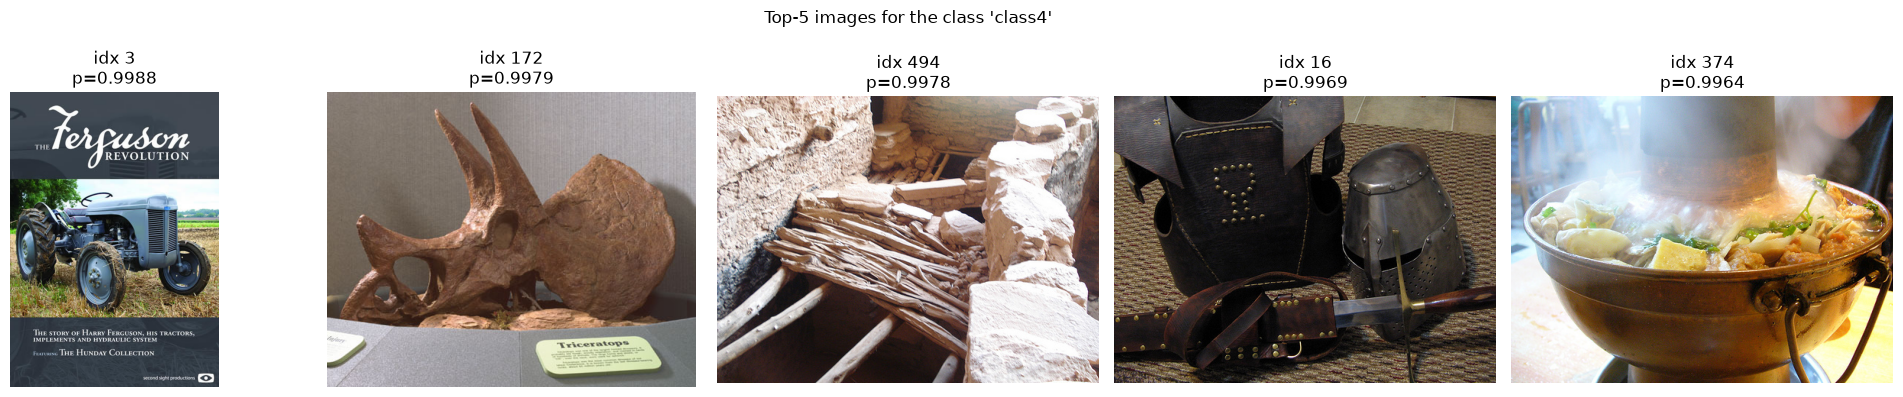

In [57]:
class_to_inspect = "class4"
top = attacks[class_to_inspect][:5]
fig, axes = plt.subplots(1, len(top), figsize=(4 * len(top), 4))

for ax, r in zip(axes, top):
    ax.imshow(train_data[r["idx"]]["image"], cmap="gray")
    ax.set_title(f"idx {r['idx']}\np={r['score']:.4f}")
    ax.axis("off")

plt.suptitle(f"Top-{len(top)} images for the class '{class_to_inspect}'")
plt.tight_layout()
plt.show()

## Attempt to do the same with wordnet

In [ ]:
import torch.nn.functional as F

CORPUS_MAX = None
CORPUS_TEMPLATES = ["{}", "an image showing {}."]
TOP = 20
CACHE_DIR = Path(".cache/surrogate"); CACHE_DIR.mkdir(parents=True, exist_ok=True)

def build_corpus():
    import nltk
    try:
        from nltk.corpus import wordnet as wn; wn.synsets("dog")
    except LookupError:
        nltk.download("wordnet", quiet=True); nltk.download("omw-1.4", quiet=True)
        from nltk.corpus import wordnet as wn
    terms, defs, seen = [], [], set()
    for pos in ("n", "a"):
        for syn in wn.all_synsets(pos):
            name = syn.lemmas()[0].name().replace("_", " ")
            if name.lower() in seen: continue
            seen.add(name.lower()); terms.append(name); defs.append(syn.definition())
    if CORPUS_MAX:
        keep = np.sort(np.random.default_rng(SEED).choice(len(terms), min(CORPUS_MAX, len(terms)), replace=False))
        terms, defs = [terms[i] for i in keep], [defs[i] for i in keep]
    return terms, defs

@torch.inference_mode()
def embed_texts(texts, bs=256):
    out = []
    for k in tqdm(range(0, len(texts), bs), desc="Text"):
        t = proc.tokenizer(texts[k:k+bs], padding=True, truncation=True,
                           return_tensors="pt").to(DEVICE)
        f = clip_backbone.get_text_features(**t)
        if isinstance(f, BaseModelOutputWithPooling):
            f = f.pooler_output
        out.append(F.normalize(f, dim=-1).float().cpu().numpy())
    return np.concatenate(out)

def unit(x): return x / np.linalg.norm(x, axis=-1, keepdims=True)

TERMS, DEFS = build_corpus()
cfile = CACHE_DIR / f"corpus_{BACKBONE.replace('/', '_')}_{len(TERMS)}.npy"
if cfile.exists():
    TC = np.load(cfile)
else:
    TC = embed_texts([t.format(x) for t in CORPUS_TEMPLATES for x in TERMS])
    TC = unit(TC.reshape(len(CORPUS_TEMPLATES), len(TERMS), -1).mean(0))
    np.save(cfile, TC)
print("corpus:", len(TERMS))

E = embeddings
Zpool = head_sk.predict(E)
sig = lambda z: 1 / (1 + np.exp(-z))
W = np.stack([1 - sig(Zpool[:,0]), sig(Zpool[:,0]), sig(Zpool[:,1]), 1 - sig(Zpool[:,1])], 1)
Ec = E - E.mean(0)
PROTO = unit((W.T @ Ec) / W.sum(0)[:, None])
CONTRAST = unit(np.stack([PROTO[1] - PROTO[0], PROTO[2] - PROTO[3]]))
TCc = unit(TC - TC.mean(0))

T_adj = unit(TC - TC.mean(0) + E.mean(0))
ZT = head_sk.predict(T_adj)
for h, (pos, neg) in enumerate([("class2","class1"), ("class3","class4")]):
    cos = TCc @ CONTRAST[h]
    r_cos = np.argsort(np.argsort(-cos)); r_log = np.argsort(np.argsort(-ZT[:, h]))
    consensus = -(r_cos + r_log) / 2.0
    o = np.argsort(-consensus)
    print(f"\n=== head {h+1}: {pos} (top) vs {neg} (bottom) — consensus ===")
    for j in o[:TOP]:  print(f"  {TERMS[j]:26s} {DEFS[j][:60]}")
    print("  ...")
    for j in o[-TOP:]: print(f"  {TERMS[j]:26s} {DEFS[j][:60]}")

corpus: 79403

=== head 1: class2 (top) vs class1 (bottom) — consensus ===
  orange zest                tiny bits of orange peel
  sulphur butterfly          any of numerous yellow or orange butterflies
  brightly-colored           having a bright color
  falun gong                 a spiritual movement that began in China in the latter half 
  orange grass               annual wiry-stemmed North American weed with minute scalelik
  sweet orange               orange with sweet juicy pulp; often has a thin skin
  colorful                   having striking color
  vibrant                    of colors that are bright and striking
  Valencia orange            variety of sweet orange cultivated extensively in Florida an
  cadmium yellow pale        pale-hued cadmium yellow pigment
  Mexican poppy              annual herb with prickly stems and large yellow flowers; sou
  sun-loving                 (of plants) flourishing in strong sunlight
  orange daisy               mat-forming herb of Tur